# Proyek Machine Learning — Prediksi Rating IMDb

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings('ignore')

print("Library berhasil di-import")

Library berhasil di-import


## 1. Import Library

In [2]:
url = "https://raw.githubusercontent.com/lilswapnil/bert-imdb-scraper/main/notebook/data/imdb_top_1000.csv"
df = pd.read_csv(url)

print("Shape dataset:", df.shape)
print("\nKolom dataset:")
print(df.columns.tolist())
df.head()

Shape dataset: (1000, 16)

Kolom dataset:
['Poster_Link', 'Series_Title', 'Released_Year', 'Certificate', 'Runtime', 'Genre', 'IMDB_Rating', 'Overview', 'Meta_score', 'Director', 'Star1', 'Star2', 'Star3', 'Star4', 'No_of_Votes', 'Gross']


,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,"28,341,469"
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,"134,966,411"
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,"534,858,444"
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,"57,300,000"
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,"4,360,000"


## 2. Load Dataset

In [3]:
print("Tipe data tiap kolom:")
print(df.dtypes)
print("\nJumlah missing value per kolom:")
print(df.isnull().sum())

Tipe data tiap kolom:
Poster_Link          str
Series_Title         str
Released_Year        str
Certificate          str
Runtime              str
Genre                str
IMDB_Rating      float64
Overview             str
Meta_score       float64
Director             str
Star1                str
Star2                str
Star3                str
Star4                str
No_of_Votes        int64
Gross                str
dtype: object

Jumlah missing value per kolom:
Poster_Link        0
Series_Title       0
Released_Year      0
Certificate      101
Runtime            0
Genre              0
IMDB_Rating        0
Overview           0
Meta_score       157
Director           0
Star1              0
Star2              0
Star3              0
Star4              0
No_of_Votes        0
Gross            169
dtype: int64


In [4]:

df['Runtime'] = df['Runtime'].str.replace(' min', '', regex=False).astype(float)


df['Gross'] = df['Gross'].astype(str).str.replace(',', '', regex=False)
df['Gross'] = pd.to_numeric(df['Gross'], errors='coerce')
df['Gross'] = df['Gross'].fillna(df['Gross'].mean())


df['Meta_score'] = df['Meta_score'].fillna(df['Meta_score'].median())

# Released_Year: pastikan numerik
df['Released_Year'] = pd.to_numeric(df['Released_Year'], errors='coerce')
df['Released_Year'] = df['Released_Year'].fillna(df['Released_Year'].median())


df['IMDB_Rating'] = pd.to_numeric(df['IMDB_Rating'], errors='coerce')
df = df.dropna(subset=['IMDB_Rating'])

print("Cleaning selesai. Shape:", df.shape)
print(df[['Runtime', 'Gross', 'Meta_score', 'Released_Year', 'IMDB_Rating']].dtypes)

Cleaning selesai. Shape: (1000, 16)
Runtime          float64
Gross            float64
Meta_score       float64
Released_Year    float64
IMDB_Rating      float64
dtype: object


## 3. Data Cleaning

In [5]:

df['Genre'] = df['Genre'].fillna('Unknown')
df['Genre_list'] = df['Genre'].str.split(', ')

mlb = MultiLabelBinarizer()
genre_encoded = pd.DataFrame(
    mlb.fit_transform(df['Genre_list']),
    columns=[f"Genre_{g}" for g in mlb.classes_]
)

print("Jumlah genre unik:", len(mlb.classes_))
print("Kolom genre hasil encoding:", genre_encoded.columns.tolist())

Jumlah genre unik: 21
Kolom genre hasil encoding: ['Genre_Action', 'Genre_Adventure', 'Genre_Animation', 'Genre_Biography', 'Genre_Comedy', 'Genre_Crime', 'Genre_Drama', 'Genre_Family', 'Genre_Fantasy', 'Genre_Film-Noir', 'Genre_History', 'Genre_Horror', 'Genre_Music', 'Genre_Musical', 'Genre_Mystery', 'Genre_Romance', 'Genre_Sci-Fi', 'Genre_Sport', 'Genre_Thriller', 'Genre_War', 'Genre_Western']


In [6]:

numeric_cols = ['Runtime', 'Released_Year', 'Meta_score', 'Gross']

X = pd.concat([
    df[numeric_cols].reset_index(drop=True),
    genre_encoded.reset_index(drop=True)
], axis=1)

y = df['IMDB_Rating'].reset_index(drop=True)

print("Shape X:", X.shape)
print("Shape y:", y.shape)

Shape X: (1000, 25)
Shape y: (1000,)


In [7]:
kolom_string = X.dtypes[X.dtypes == 'object']

if len(kolom_string) == 0:
    print("✅ AMAN: Tidak ada kolom string di X. Siap training.")
else:
    print("❌ MASIH ADA kolom string:")
    print(kolom_string)
    raise ValueError("Perbaiki dulu kolom string sebelum lanjut!")

✅ AMAN: Tidak ada kolom string di X. Siap training.


## 4. Encoding Genre

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (800, 25)
X_test : (200, 25)
y_train: (800,)
y_test : (200,)


## 5. Feature Engineering

In [9]:
from sklearn.metrics import root_mean_squared_error

models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

hasil = {}

for nama, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    rmse = root_mean_squared_error(y_test, y_pred)
    mae  = mean_absolute_error(y_test, y_pred)
    r2   = r2_score(y_test, y_pred)

    hasil[nama] = {'RMSE': rmse, 'MAE': mae, 'R2': r2}
    print(f"{nama}")
    print(f"  RMSE : {rmse:.4f}")
    print(f"  MAE  : {mae:.4f}")
    print(f"  R²   : {r2:.4f}")
    print()

Linear Regression
  RMSE : 0.2510
  MAE  : 0.2108
  R²   : 0.0173

Random Forest
  RMSE : 0.2314
  MAE  : 0.1854
  R²   : 0.1650

Gradient Boosting
  RMSE : 0.2380
  MAE  : 0.1960
  R²   : 0.1165



In [10]:
df_hasil = pd.DataFrame(hasil).T
df_hasil = df_hasil.sort_values('RMSE')
print("Perbandingan Model (diurutkan dari RMSE terkecil):")
print(df_hasil)

Perbandingan Model (diurutkan dari RMSE terkecil):
                       RMSE       MAE        R2
Random Forest      0.231364  0.185405  0.164963
Gradient Boosting  0.237986  0.195969  0.116480
Linear Regression  0.250989  0.210782  0.017294


## 6. Train-Test Split

In [11]:
print("Cross-Validation (5-fold) pada RMSE:\n")
for nama, model in models.items():
    scores = cross_val_score(
        model, X, y,
        cv=5,
        scoring='neg_root_mean_squared_error'
    )
    print(f"{nama}: RMSE rata-rata = {-scores.mean():.4f} (+/- {scores.std():.4f})")

Cross-Validation (5-fold) pada RMSE:

Linear Regression: RMSE rata-rata = 0.2886 (+/- 0.1730)
Random Forest: RMSE rata-rata = 0.3062 (+/- 0.1342)
Gradient Boosting: RMSE rata-rata = 0.2975 (+/- 0.1352)


## 7. Model Training

In [12]:
rf = models['Random Forest']

importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Top 10 Feature Importance:")
print(importance.head(10))

Top 10 Feature Importance:
Runtime           0.213442
Meta_score        0.205601
Gross             0.196061
Released_Year     0.166218
Genre_Sci-Fi      0.021548
Genre_Crime       0.020554
Genre_Drama       0.015939
Genre_War         0.014911
Genre_Thriller    0.014758
Genre_Action      0.014645
dtype: float64


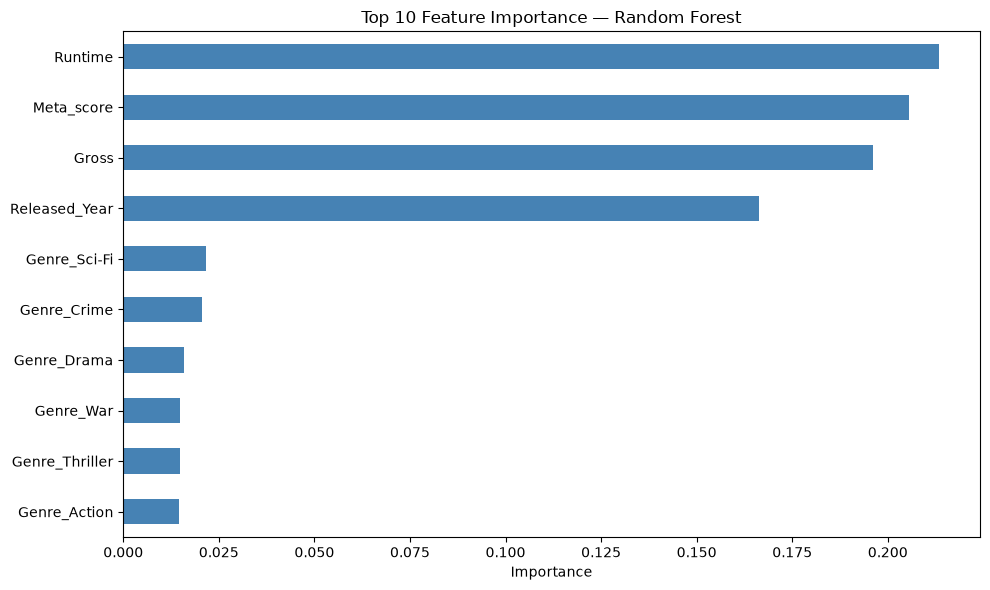

In [13]:
plt.figure(figsize=(10, 6))
importance.head(10).plot(kind='barh', color='steelblue')
plt.xlabel('Importance')
plt.title('Top 10 Feature Importance — Random Forest')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 8. Feature Importance

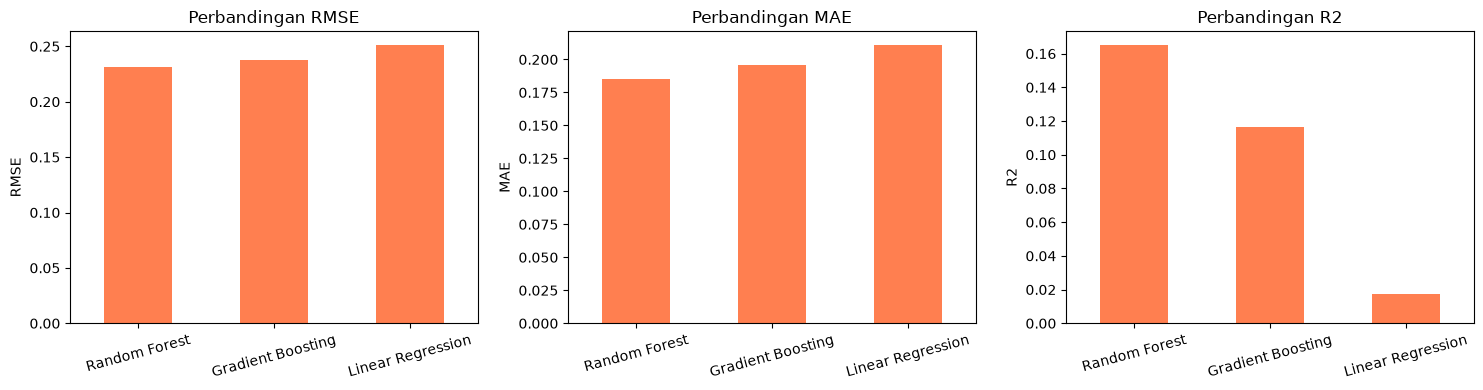

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, metrik in enumerate(['RMSE', 'MAE', 'R2']):
    df_hasil[metrik].plot(kind='bar', ax=axes[i], color='coral')
    axes[i].set_title(f'Perbandingan {metrik}')
    axes[i].set_ylabel(metrik)
    axes[i].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## 9. Visualisasi

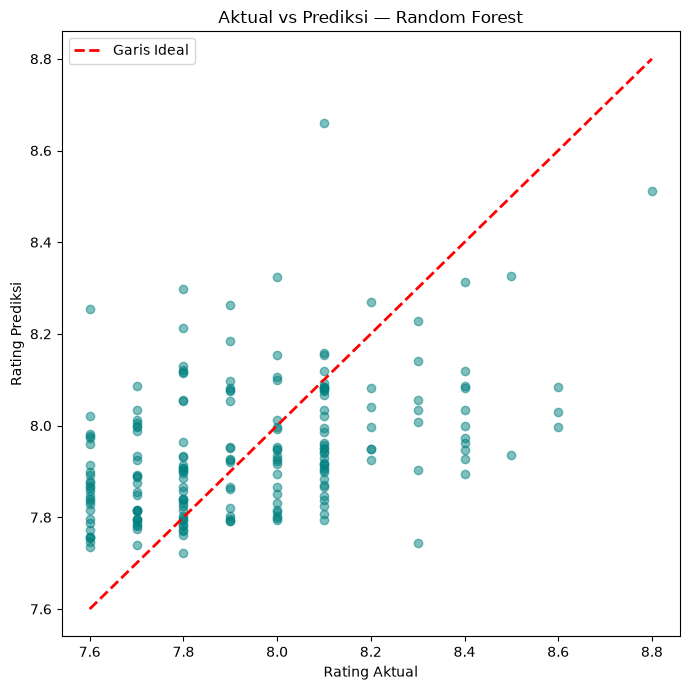

In [15]:
y_pred_rf = models['Random Forest'].predict(X_test)

plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred_rf, alpha=0.5, color='teal')
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'r--', linewidth=2, label='Garis Ideal')
plt.xlabel('Rating Aktual')
plt.ylabel('Rating Prediksi')
plt.title('Aktual vs Prediksi — Random Forest')
plt.legend()
plt.tight_layout()
plt.show()

## 10. Kesimpulan

1. Model terbaik berdasarkan RMSE adalah Random Forest dengan RMSE = 0.2314.
2. Fitur paling berpengaruh terhadap prediksi rating adalah 
   **Meta_score**, **Gross**, dan **Runtime**.
3. Scatter plot aktual vs prediksi menunjukkan model cukup baik dalam mengikuti
   tren, meskipun prediksi cenderung mengumpul di rentang 7.6–8.4.
4. Keterbatasan: dataset hanya 1000 film, tidak representatif untuk seluruh film IMDb.
